The task is to initialize PRESS for one match, browse team possessions, select any usable frame, compute its quantities and retrieve/plot results. Initialization prepares validated inputs and empty result stores; the physics solvers and learned models run when requested. **design choice**

This notebook executes from start to finish without match downloads. Every input is synthetic, including the 22-player tracking table and xT surface. Small candidate grids keep the demo quick and are not a benchmark configuration. For a local match, replace `load_demo_match()` with the processed-file adapter in the [match guide](../../usage.qmd). The [API reference](../../api.qmd) describes arguments, results and errors.

Team-possession IDs remain unchanged across a completed pass and a carrier change. Frame getters return tracking rows; checkpoint getters select action starts with known context. The default possession evaluator includes canonical starts and additional evaluation snapshots, labeled by `is_canonical` and `checkpoint_kind`. `include_snapshots=False` keeps canonical rows; `frame_ids` accepts another selection. A retrospective survival product depends on that selection; denser sampling is not automatically a calibrated alternative.


team possessions:
  possession_id team_id  frame_start  frame_end  lost
             1    home            0         29  True
             2    away           30         39 False
selected checkpoints:
  frame_start  frame_end     action     start_type previous_action  time_since_start  frame_id  is_canonical checkpoint_kind      start_type_std previous_action_std  eligible
           0          9 ball_drive pass_reception  pass_reception               0.0         0          True       canonical reception_open_play reception_open_play      True
          10         19 ball_drive pass_reception  pass_reception               0.0        10          True       canonical reception_open_play reception_open_play      True
          20         29 ball_drive pass_reception      ball_drive               1.0        20          True       canonical reception_open_play          ball_drive      True
one wide frame: (1, 119)
state carrier: home_7


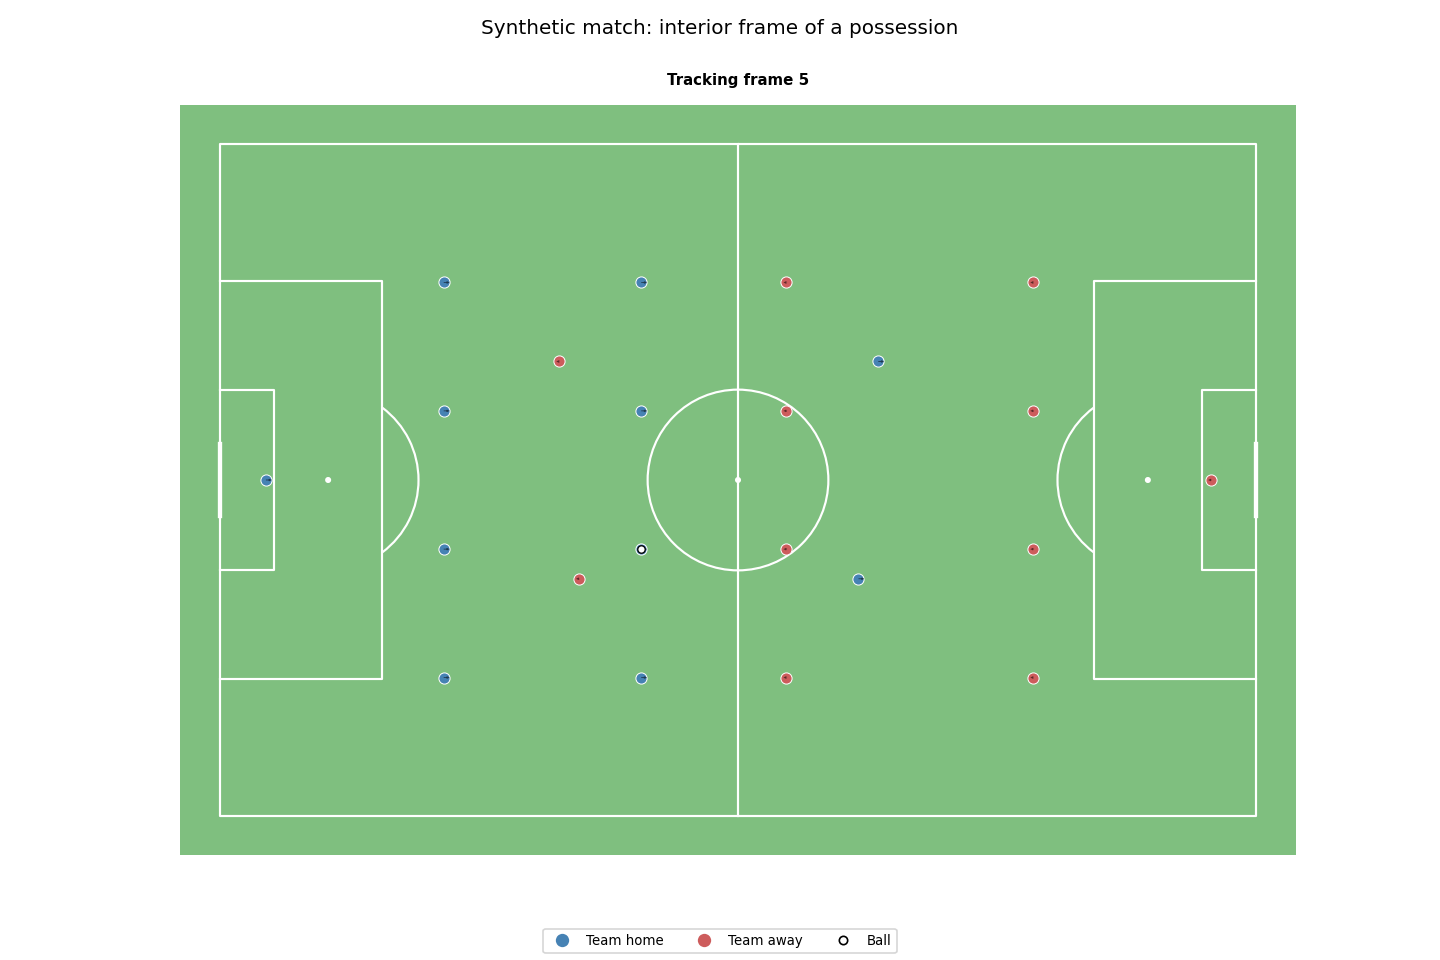

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.visualization import plot_frame
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
print("team possessions:\n", model.get_possessions().to_string(index=False))
print("selected checkpoints:\n", model.get_checkpoints(possession_id).to_string(index=False))
print("one wide frame:", model.get_frame(frame_id).shape)
print("state carrier:", model.get_state(frame_id)["player"])
plot_frame(model, frame_id)
fig = plt.gcf()
fig.suptitle("Synthetic match: interior frame of a possession")
out = Path("figures/vignette_00_match_workflow.png")
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=150)
fig.savefig(out.with_suffix(".svg"))


## Compute and retrieve the frame

`compute_frame` runs pitch control, drive loss, transition choice, optional BCOS, action selection and hazard in dependency order. BCOS remains outside the core PRESS class; the convenience method uses the extra only to supply the scalar feature expected by the action-selection model. The dictionaries returned here are the same core outputs exposed by the result getters.


In [5]:
print("interior-frame context:", model.get_frame_context(frame_id))
assert frame_id not in model.get_checkpoints(possession_id).frame_id.to_list()
result = model.compute_frame(frame_id, xT_grid,
    ppcf_kwargs={"r_max": 12, "step": 6}, bcos_kwargs={"r_max": 8, "step": 4})
print("available components:", list(result))
print("P(pass):", model.get_action_selection_result(frame_id)["Pass probability"])
print("drive risk:", float(model.get_ball_drive_result(frame_id)["Ball drive loss probability"]))
print("hazard:", model.get_hazard_result(frame_id))


interior-frame context: {'start_type': 'pass_reception', 'previous_action': 'pass_reception', 'completed_canonical_drives': 0, 'source': 'action_interval'}
available components: ['PPCF', 'PI', 'ACTION_SELECTION', 'HAZARD']
P(pass): 0.48850399255752563
drive risk: 0.0012922491987474483
hazard: {'Hazard': 0.012514264786956159, 'Drive risk': 0.0012922491987474483, 'Pass failure expected': 0.02426445773578867, 'rppcf': 0.9757355422642113}


## Next tasks

Use [drive risk](../01_ball_drive_risk/01_ball_drive_risk.ipynb), [pass probability](../02_pass_probability/02_pass_probability.ipynb), [transition choice](../03_transition_model/03_pass_selection.ipynb) and [action selection](../04_action_selection/04_action_selection.ipynb) to inspect individual components. Continue with [checkpoint setup](../setup/possession_and_checkpoint_setup.ipynb), [survival](../07_case_studies/07_case_studies.ipynb), [typologies](../07_case_studies/07_case_studies.ipynb) and [league reporting](../07_case_studies/07_case_studies.ipynb). For an arbitrary frame, context comes from per-frame annotations or the containing action interval; explicit overrides are also supported. See the match guide.
